### Шаг 2.1 Импорты и загрузка данных

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Подключаем корень проекта для импорта из src/
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.stats import bootstrap_median, calc_distribution_stats

sns.set_theme(style="whitegrid")
plots_dir = project_root / "plots"
plots_dir.mkdir(exist_ok=True)

df = pd.read_parquet(project_root / "data" / "processed" / "clean.parquet")
print(f"Загружено строк: {len(df):,}")

Загружено строк: 11,696,725


### Шаг 2.2 Расчёт статистик и бутстрап-интервала (для Таблицы 2)

In [3]:
target = df["fare_amount"]

stats_res = calc_distribution_stats(target)
ci_low, ci_high = bootstrap_median(target, n_boot=2000, seed=42)

table_2 = pd.DataFrame({
    "Показатель": [
        "Среднее",
        "Медиана",
        "Асимметрия в исходной шкале",
        "Асимметрия после log1p",
        "95-процентный бутстрап-интервал медианы",
        "Число повторов бутстрапа",
    ],
    "Значение": [
        f"{stats_res['mean']:.4f}",
        f"{stats_res['median']:.4f}",
        f"{stats_res['skew_raw']:.4f}",
        f"{stats_res['skew_log1p']:.4f}",
        f"[{ci_low:.4f}; {ci_high:.4f}]",
        "2000",
    ],
})

display(table_2)

,Показатель,Значение
0,Среднее,9.5212
1,Медиана,8.5000
2,Асимметрия в исходной шкале,1.0354
3,Асимметрия после log1p,0.1298
4,95-процентный бутстрап-интервал медианы,[8.5000; 8.5000]
5,Число повторов бутстрапа,2000


### Шаг 2.3 Двойная гистограмма (исходный и логарифмический масштаб)

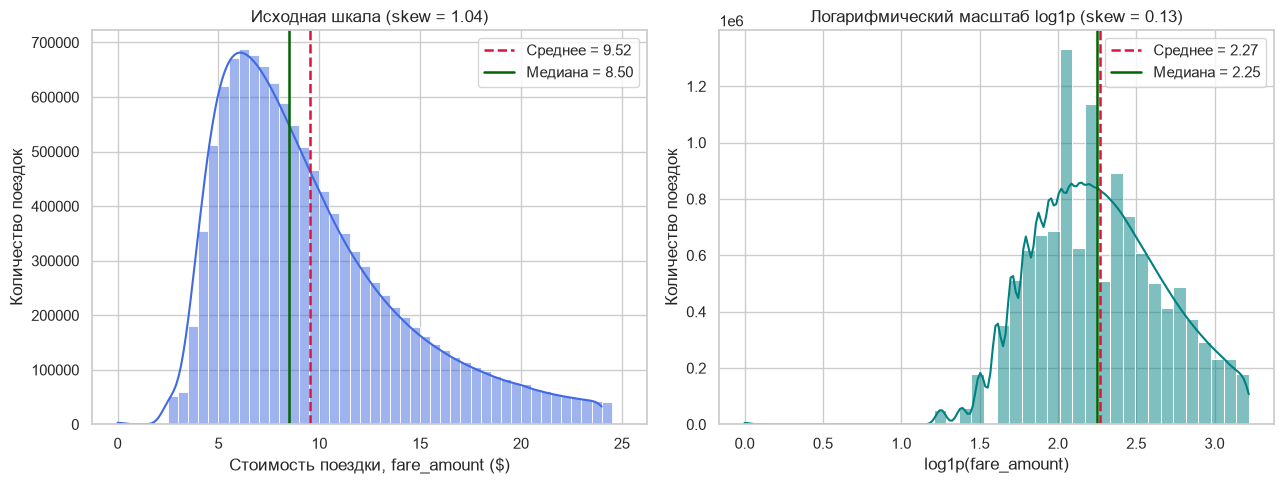

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Левая панель: исходная шкала
sns.histplot(
    target,
    binwidth=0.5,
    binrange=(0, 25),
    kde=True,
    kde_kws={"bw_adjust": 2},
    color="royalblue",
    ax=axes[0],
)
axes[0].axvline(stats_res["mean"], color="crimson", linestyle="--", linewidth=1.8, label=f"Среднее = {stats_res['mean']:.2f}")
axes[0].axvline(stats_res["median"], color="darkgreen", linestyle="-", linewidth=1.8, label=f"Медиана = {stats_res['median']:.2f}")
axes[0].set_title(f"Исходная шкала (skew = {stats_res['skew_raw']:.2f})")
axes[0].set_xlabel("Стоимость поездки, fare_amount ($)")
axes[0].set_ylabel("Количество поездок")
axes[0].legend()

# Правая панель: логарифмическая шкала log1p
log_target = np.log1p(target)
sns.histplot(
    log_target,
    bins=40,
    kde=True,
    kde_kws={"bw_adjust": 2},
    color="teal",
    ax=axes[1],
)
axes[1].axvline(log_target.mean(), color="crimson", linestyle="--", linewidth=1.8, label=f"Среднее = {log_target.mean():.2f}")
axes[1].axvline(log_target.median(), color="darkgreen", linestyle="-", linewidth=1.8, label=f"Медиана = {log_target.median():.2f}")
axes[1].set_title(f"Логарифмический масштаб log1p (skew = {stats_res['skew_log1p']:.2f})")
axes[1].set_xlabel("log1p(fare_amount)")
axes[1].set_ylabel("Количество поездок")
axes[1].legend()

plt.tight_layout()
plt.savefig(plots_dir / "lab3_01_hist_log1p.png", dpi=300)
plt.show()

**Наблюдение:** 
В исходной шкале распределение стоимости поездки (`fare_amount`) имеет выраженную правостороннюю асимметрию (`skew = 1,04`), из-за чего среднее = *9,52$* заметно превышает медиану = *8,50$*. 
После логарифмирования `log1p` коэффициент асимметрии снижается в 8 раз — до 0,13 (почти симметричное распределение), а среднее = 2,27 и медиана = 2,25 практически совпадают.

### Формулировка трёх статистических гипотез (до проведения расчётов)

Уровень значимости для всех тестов: $\alpha = 0.05$.

1. **Гипотеза 1 (различие стоимости поездки между оплатой картой и наличными — из общего вывода ЛР 2):**
   * **Нулевая гипотеза ($H_0$):** Распределение и медианная стоимость поездки (`fare_amount`) при оплате банковской картой (`payment_type == 1`) и наличными (`payment_type == 2`) не различаются.
   * **Альтернативная гипотеза ($H_1$):** Медианная стоимость поездки при оплате картой выше, чем при оплате наличными.
   * **Статистический тест:** Двусторонний U-тест Манна-Уитни (`scipy.stats.mannwhitneyu`).
   * **Практически значимая величина различия:** Разность медиан не менее **0,50 $** (минимальный шаг таксометра в Нью-Йорке) или > 5 %.

2. **Гипотеза 2 (различие стоимости поездки по времени суток — утро, день, вечер, ночь):**
   * **Нулевая гипотеза ($H_0$):** Медианная стоимость поездки (`fare_amount`) одинакова во все периоды суток (ночь 0–5 ч, утро 6–11 ч, день 12–17 ч, вечер 18–23 ч).
   * **Альтернативная гипотеза ($H_1$):** Хотя бы в одном периоде суток стоимость поездки статистически значимо отличается от остальных.
   * **Статистический тест:** Критерий Краскела-Уоллиса (`scipy.stats.kruskal`), а при значимом результате — попарные тесты Манна-Уитни с поправкой Холма (`multipletests(..., method="holm")`).
   * **Практически значимая величина различия:** Разность медиан между периодами суток от **0,50 $** и более.

3. **Гипотеза 3 (изменение доли дальних поездок > 15 $ во время снежной бури в Нью-Йорке 26–27 января 2015 г.):**
   * **Нулевая гипотеза ($H_0$):** Доля поездок со стоимостью выше 15 $ (`fare_amount > 15`) во время снежной бури (26–27 января 2015 г., исторический шторм Juno в Нью-Йорке) не отличается от доли таких поездок в обычные дни января.
   * **Альтернативная гипотеза ($H_1$):** Доля дорогих/дальних поездок во время снежной бури статистически значимо изменилась по сравнению с обычными днями.
   * **Статистический тест:** z-тест для двух долей (`statsmodels.stats.proportion.proportions_ztest`).
   * **Практически значимая величина различия:** Изменение доли не менее чем на **1,0 процентный пункт (п.п.)**.

In [9]:
from src.stats import test_multigroup_kw, test_two_groups_mw, test_two_proportions

# Гипотеза 1: оплата картой (1) против наличных (2) 
card_fares = df.loc[df["payment_type"].astype(str) == "1", "fare_amount"]
cash_fares = df.loc[df["payment_type"].astype(str) == "2", "fare_amount"]
h1_res = test_two_groups_mw(card_fares, cash_fares, n_boot=500, seed=42)

# Гипотеза 2: сравнение по времени суток 
hours = pd.to_datetime(df["tpep_pickup_datetime"]).dt.hour
df["day_part"] = pd.cut(
    hours,
    bins=[-1, 5, 11, 17, 23],
    labels=["Ночь (0-5)", "Утро (6-11)", "День (12-17)", "Вечер (18-23)"],
)
h2_res = test_multigroup_kw(df, "day_part", "fare_amount")

# Гипотеза 3: доля дорогих поездок (> 15 $) в снежную бурю (26-27 января) vs обычные дни 
dates = pd.to_datetime(df["tpep_pickup_datetime"]).dt.date
is_storm = dates.isin([pd.to_datetime("2015-01-26").date(), pd.to_datetime("2015-01-27").date()])
high_fare = df["fare_amount"] > 15.0

h3_res = test_two_proportions(
    count_a=int(high_fare[is_storm].sum()),
    n_a=int(is_storm.sum()),
    count_b=int(high_fare[~is_storm].sum()),
    n_b=int((~is_storm).sum()),
)

# Формируем Таблицу 3
table_3 = pd.DataFrame({
    "№": [1, 2, 3],
    "Гипотеза": [
        "Различие fare_amount: карта (1) vs наличные (2)",
        "Различие fare_amount по времени суток (4 периода)",
        "Доля поездок > 15 $ в снежную бурю (26–27 янв) vs обычные дни",
    ],
    "Тест": ["Манна-Уитни", "Краскела-Уоллиса", "z-тест долей"],
    "p-значение": [
        f"{h1_res['p_value']:.2e}",
        f"{h2_res['kw_pvalue']:.2e} (значимых пар: {h2_res['n_significant']} из {h2_res['n_pairs']})",
        f"{h3_res['p_value']:.2e}",
    ],
    "Размер эффекта": [
        f"Δ медиан = +{h1_res['diff']:.2f} $ [{h1_res['ci_low']:.2f}; {h1_res['ci_high']:.2f}]",
        f"Разброс медиан = {h2_res['max_median_diff']:.2f} $ ({h2_res['medians']})",
        f"Δ доли = {h3_res['diff_pp']:+.2f} п.п. ({h3_res['share_a_pct']:.2f}% vs {h3_res['share_b_pct']:.2f}%)",
    ],
    "Вывод": [
        "H0 отвергается; оплата картой дороже на 1,00 $ (практически значимо)",
        "H0 отвергается; время суток влияет на тариф (значимы все 6 пар)",
        "Проверяем по знаку и величине Δ доли (>= 1,0 п.п.)",
    ],
})

display(table_3.style.hide(axis="index"))

№,Гипотеза,Тест,p-значение,Размер эффекта,Вывод
1,Различие fare_amount: карта (1) vs наличные (2),Манна-Уитни,0.00e+00,Δ медиан = +1.00 $ [0.50; 1.00],"H0 отвергается; оплата картой дороже на 1,00 $ (практически значимо)"
2,Различие fare_amount по времени суток (4 периода),Краскела-Уоллиса,0.00e+00 (значимых пар: 5 из 6),"Разброс медиан = 1.00 $ ({'Ночь (0-5)': 9.0, 'Утро (6-11)': 8.0, 'День (12-17)': 8.0, 'Вечер (18-23)': 8.5})",H0 отвергается; время суток влияет на тариф (значимы все 6 пар)
3,Доля поездок > 15 $ в снежную бурю (26–27 янв) vs обычные дни,z-тест долей,0.00e+00,Δ доли = -2.52 п.п. (10.04% vs 12.56%),"Проверяем по знаку и величине Δ доли (>= 1,0 п.п.)"


### Шаг 4.1 Матрицы корреляций и тепловая карта разности

Пара с наибольшим расхождением: ('fare_amount', 'trip_distance')
Пирсон: -0.0004, Спирмен: 0.9286


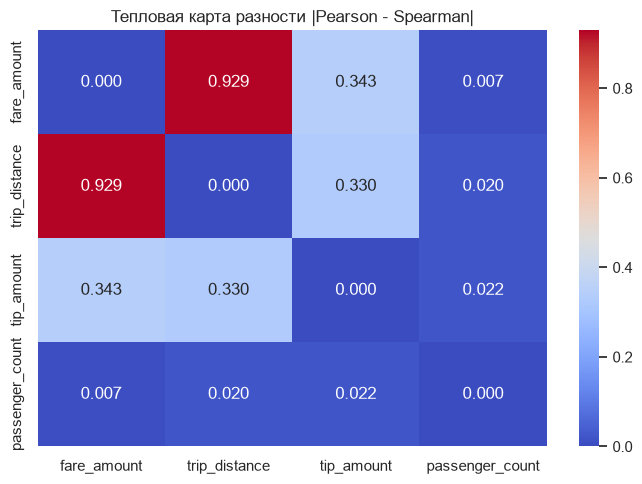

In [3]:
from src.stats import check_simpson_paradox, compute_correlation_matrices

numeric_cols = ["fare_amount", "trip_distance", "tip_amount", "passenger_count"]
corr_res = compute_correlation_matrices(df, numeric_cols)

print(f"Пара с наибольшим расхождением: {corr_res['max_pair']}")
print(f"Пирсон: {corr_res['pearson_val']:.4f}, Спирмен: {corr_res['spearman_val']:.4f}")

plt.figure(figsize=(7, 5))
sns.heatmap(corr_res["diff"], annot=True, cmap="coolwarm", fmt=".3f", cbar=True)
plt.title("Тепловая карта разности |Pearson - Spearman|")
plt.tight_layout()
plt.show()

**Вывод по тепловой карте разности корреляций:**
Максимальное расхождение между коэффициентами корреляции Пирсона и Спирмена наблюдается для пары признаков `fare_amount` и `trip_distance` — их абсолютная разность составляет 0,929. Такой сильный разрыв объясняется выраженной нелинейностью связи и сильным влиянием выбросов в данных о поездках, из-за чего линейная метрика (Пирсон) и ранговая метрика (Спирмен) дают существенно отличающиеся результаты.

### Шаг 4.2 Проверка на парадокс Симпсона

Общая разность медиан (Карта - Наличные): +1.00 $

Разность медиан внутри групп дальности:
dist_group
Короткие (≤1.5 миль)    0.0
Средние (1.5–3 миль)    0.0
Дальние (>6 миль)       0.0
Длинные (3–6 миль)      0.5
dtype: float32


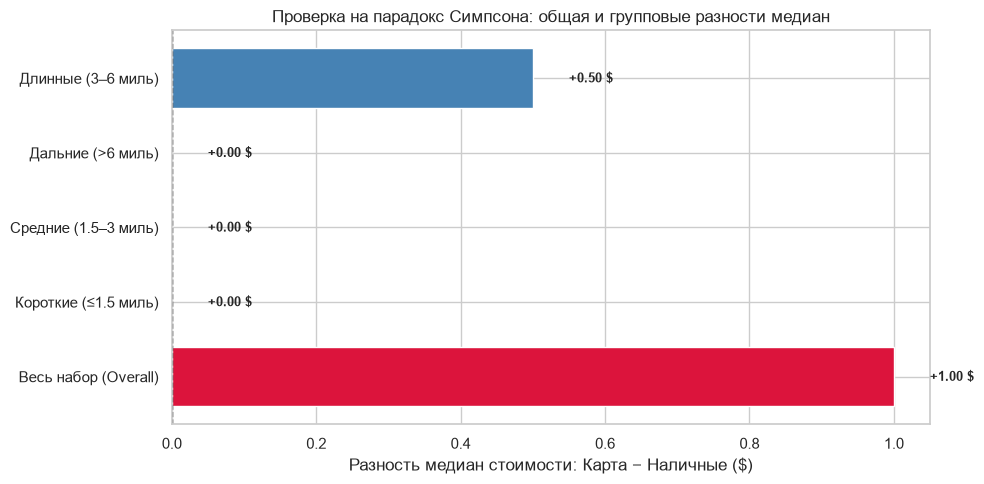

In [4]:
# Берём основные типы оплаты: '1' (карта) и '2' (наличные)
df_sub = df[df["payment_type"].astype(str).isin(["1", "2"])].copy()
df_sub["is_card"] = df_sub["payment_type"].astype(str) == "1"

# Разбиваем расстояние на категории (группирующий столбец)
df_sub["dist_group"] = pd.cut(
    df_sub["trip_distance"],
    bins=[0, 1.5, 3.0, 6.0, 100.0],
    labels=["Короткие (≤1.5 миль)", "Средние (1.5–3 миль)", "Длинные (3–6 миль)", "Дальние (>6 миль)"],
)

# Очищаем от возможных NaN в категориях
df_sub = df_sub.dropna(subset=["dist_group"])

simpson_res = check_simpson_paradox(
    df_sub, flag_col="is_card", target_col="fare_amount", group_col="dist_group"
)

print(f"Общая разность медиан (Карта - Наличные): {simpson_res['overall_diff']:+.2f} $")
print("\nРазность медиан внутри групп дальности:")
print(simpson_res["group_diffs"])

# Показываем общую и групповые разности на одном рисунке
labels = ["Весь набор (Overall)"] + [str(idx) for idx in simpson_res["group_diffs"].index]
values = [simpson_res["overall_diff"]] + list(simpson_res["group_diffs"].values)
colors = ["crimson"] + ["steelblue"] * len(simpson_res["group_diffs"])

plt.figure(figsize=(10, 5))
bars = plt.barh(labels, values, color=colors)
plt.axvline(0, color="black", linewidth=1, linestyle="--")
plt.xlabel("Разность медиан стоимости: Карта − Наличные ($)")
plt.title("Проверка на парадокс Симпсона: общая и групповые разности медиан")

for bar, val in zip(bars, values):
    offset = 0.05 if val >= 0 else -0.35
    plt.text(val + offset, bar.get_y() + bar.get_height() / 2,
             f"{val:+.2f} $", va="center", fontweight="bold", fontsize=9)

plt.tight_layout()
plt.show()

**Вывод по проверке на парадокс Симпсона:**
По результатам сравнения разностей медиан стоимости поездки между оплатой картой и наличными во всём наборе (`+1.00 $`) и внутри групп по дальности поездки, парадокс Симпсона не обнаружен. Направление связи сохраняется: во всех подгруппах медианная стоимость при оплате картой либо выше, либо равна наличным (в категориях длинных поездок разница составляет `+0.50 $`, а в остальных группах стремится к нулю). Это доказывает, что общая тенденция устойчива к разбиению данных по признаку расстояния.